# Do what students say match how much they use AI?

## Idea

We looked at three reasons students hold back from using AI: 

Internal (Personal) Reasons: "I want to learn the material myself", "I don't trust its answers" 

External Reasons: "My class rules don't allow it"

We expect that the more students say a reason holds them back, they will use AI less. We want to see how it holds up for all three reasons.

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../../data/uncleaned_data.csv")

# answers use a curly apostrophe (’), swap it for a normal one (')
df = df.replace("’", "'", regex=True)

## Data Cleaning

To compare students we needed one number for how much each student uses AI (AI-reliance score).

- [CA]–[CH] "How often do you use AI for the following" asked about 8 tasks, each with 4 options (I don't use AI for this | I use it rarely | I use it sometimes | I use it very often).  
Each becomes a value 0–3 and averaged them, so each student gets one **AI-reliance score** from 0 (never) to 3 (very often). Blanks and "Prefer not to answer" were skipped.

We then focused on the questions that put these students into the different groups that we will be observing.

- [DE] "I want to learn the material myself," [DG] "I don't trust its answers," and [DH] "My class rules don't allow it".  
Each had 4 options (Not at all | A little | Somewhat | A lot).  
"Not at all" and "A little" were small groups so they got combined. "Somewhat" and "A lot" were left as is.

In [2]:
# look through the df to find the 8 "how often do you use AI for..." columns
ai_cols = [c for c in df.columns if c.startswith("How often do you use AI for the following:")]

# look through the df to find the 3 reason columns
learn_col = [c for c in df.columns if "learn the material myself" in c][0]
trust_col = [c for c in df.columns if "trust its answers" in c][0]   # "don't trust its answers"
rules_col = [c for c in df.columns if "class rules" in c][0]

# turn each ai use answer into a number, anything else (blank, prefer not to answer) becomes NaN
to_number = {
    "I don't use AI for this": 0,
    "I use it rarely": 1,
    "I use it sometimes": 2,
    "I use it very often": 3,
}
numbers = pd.DataFrame()
for col in ai_cols:
    numbers[col] = df[col].map(to_number)

# break down the groups like stated in the above markdown cell
reason_groups = {
    "Not at all": "Not at all / A little",
    "A little": "Not at all / A little",
    "Somewhat": "Somewhat",
    "A lot": "A lot",
}

# One row per student with their reliance score (average of the 8 numbers, NaNs skipped) and their three grouped answers.
# NaNs are kept here, seaborn drops them for each panel on its own.
data = pd.DataFrame({
    "reliance_score": numbers.mean(axis=1),
    "learn_myself": df[learn_col].map(reason_groups),
    "no_trust": df[trust_col].map(reason_groups),
    "class_rules": df[rules_col].map(reason_groups),
})

## Build and Plot

I want to learn the material myself
                       count  median
learn_myself                        
Not at all / A little     23    2.25
Somewhat                  25    1.75
A lot                     36    1.38

I don't trust its answers
                       count  median
no_trust                            
Not at all / A little     40    2.00
Somewhat                  32    1.75
A lot                     12    0.50

My class rules don't allow it
                       count  median
class_rules                         
Not at all / A little     29    1.38
Somewhat                  26    1.75
A lot                     28    1.75



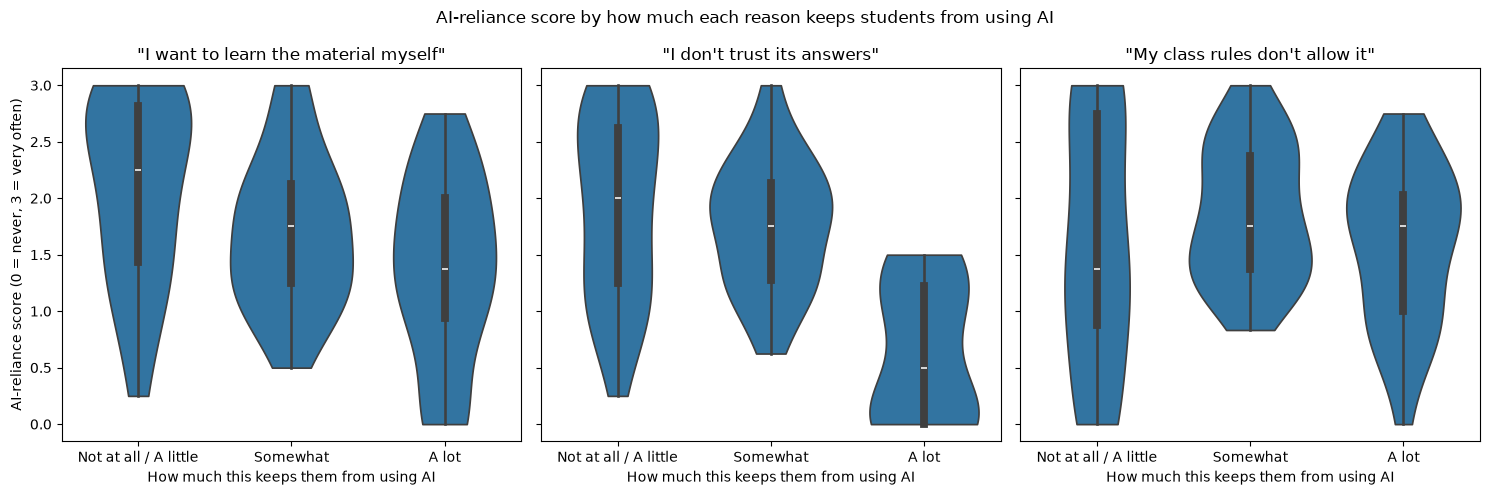

In [3]:
# violin ordering
order = ["Not at all / A little", "Somewhat", "A lot"]

# panel title -> column in data
reasons = {
    "I want to learn the material myself": "learn_myself",
    "I don't trust its answers": "no_trust",
    "My class rules don't allow it": "class_rules",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

i = 0
for title, col in reasons.items():
    sns.violinplot(data=data, x=col, y="reliance_score", order=order, cut=0, ax=axes[i])
    axes[i].set_title(f'"{title}"')
    axes[i].set_xlabel("How much this keeps them from using AI")

    # number of students and median score for each group
    print(title)
    print(data.groupby(col)["reliance_score"].agg(["count", "median"]).loc[order].round(2))
    print()

    i += 1

axes[0].set_ylabel("AI-reliance score (0 = never, 3 = very often)")
fig.suptitle("AI-reliance score by how much each reason keeps students from using AI")
plt.tight_layout()
plt.show()

## Conclusion

Each panel is one reason, and each violin is a group of students based on how much that reason keeps them from using AI. The height shows their AI-reliance score. For the two reasons that come from the student, it is clear that as we move from left to right the scores drop: wanting to learn the material myself (median 2.25 $\rightarrow$ 1.75 $\rightarrow$ 1.38) and not trusting its answers (2.00 $\rightarrow$ 1.75 $\rightarrow$ 0.50, though only 12 students said "A lot"). For class rules the scores don't drop, if anything they go up slightly (1.38 $\rightarrow$ 1.75 $\rightarrow$ 1.75). What this can tell us is that a student's own reasons line up with how much they use AI, while class rules don't seem to.